In [1]:
import os
import json
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def get_project_root():
    current = Path.cwd().resolve()
    for path in [current, *current.parents]:
        if (path / "pyproject.toml").exists() or (path / ".git").exists():
            return path
    return current

PROJECT_ROOT = get_project_root()
FEATURES_DIR = PROJECT_ROOT / "data" / "gold" / "features"
GOLD_OUTPUT_DIR = PROJECT_ROOT / "data" / "gold" / "drought_forecasting"
MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_EVAL_DIR = PROJECT_ROOT / "reports" / "evaluation"
REPORTS_FIG_DIR = PROJECT_ROOT / "reports" / "figures"

for directory in (GOLD_OUTPUT_DIR, MODELS_DIR, REPORTS_EVAL_DIR, REPORTS_FIG_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print("Đã khởi tạo đầy đủ các thư mục lưu trữ.")

Project root: /Users/duonghhoangnam/Drought-Prediction
Đã khởi tạo đầy đủ các thư mục lưu trữ.


In [2]:
parquet_path = FEATURES_DIR / "gold_drought_features.parquet"
csv_path = FEATURES_DIR / "gold_drought_features.csv"

if parquet_path.exists():
    try:
        df = pd.read_parquet(parquet_path)
        print(f"-> Đọc thành công từ Parquet: {parquet_path}")
    except Exception as error:
        print(f"Parquet engine lỗi ({error}); chuyển sang đọc file CSV...")
        df = pd.read_csv(csv_path)
elif csv_path.exists():
    df = pd.read_csv(csv_path)
    print(f"-> Đọc thành công từ CSV: {csv_path}")
else:
    raise FileNotFoundError(
        "Không tìm thấy file gold_drought_featues (.parquet hoặc .csv)."
    )

if "valid_time" in df.columns:
    df["valid_time"] = pd.to_datetime(df["valid_time"])
if "year" not in df.columns:
    df["year"] = df["valid_time"].dt.year
if "month" not in df.columns:
    df["month"] = df["valid_time"].dt.month

features = [
    "year", "latitude", "longitude", "temp_mean_celsius",
    "precip_monthly_mm", "water_balance_mm", "soil_moisture_surface",
    "soil_moisture_rootzone", "spi_3m", "precip_lag_1m",
    "precip_lag_2m", "spei_3m_lag_1m", "spei_3m_lag_2m",
    "month_sin", "month_cos",
]

print(f"Loaded: {csv_path}")
print(f"Kích thước tập dữ liệu: {df.shape[0]} hàng, {df.shape[1]} cột")
print(f"Số lượng đặc trưng sử dụng ({len(features)} biến): {features}")
df.head(3)

-> Đọc thành công từ Parquet: /Users/duonghhoangnam/Drought-Prediction/data/gold/features/gold_drought_features.parquet
Loaded: /Users/duonghhoangnam/Drought-Prediction/data/gold/features/gold_drought_features.csv
Kích thước tập dữ liệu: 100082 hàng, 16 cột
Số lượng đặc trưng sử dụng (15 biến): ['year', 'latitude', 'longitude', 'temp_mean_celsius', 'precip_monthly_mm', 'water_balance_mm', 'soil_moisture_surface', 'soil_moisture_rootzone', 'spi_3m', 'precip_lag_1m', 'precip_lag_2m', 'spei_3m_lag_1m', 'spei_3m_lag_2m', 'month_sin', 'month_cos']


,valid_time,year,month,latitude,longitude,temp_mean_celsius,precip_monthly_mm,water_balance_mm,soil_moisture_surface,soil_moisture_rootzone,spi_3m,spei_3m,precip_lag_1m,precip_lag_2m,spei_3m_lag_1m,spei_3m_lag_2m
0,2000-06-01,2000,6,8.6,104.8,27.023956,405.521965,223.868909,0.301346,0.304657,0.816445,0.762089,249.647833,141.970725,-0.406900,-0.914036
1,2000-07-01,2000,7,8.6,104.8,27.195587,212.653884,1.288602,0.263580,0.252380,1.037827,0.955350,405.521965,249.647833,0.762089,-0.406900
2,2000-08-01,2000,8,8.6,104.8,26.924713,297.492192,79.011011,0.282471,0.235382,1.187677,1.086303,212.653884,405.521965,0.955350,0.762089


In [3]:
target_col = "spei_3m"
if target_col not in df.columns:
    raise KeyError(f"Target column {target_col!r} is missing from the dataset.")

df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12)
df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12)

df = df.sort_values(["latitude", "longitude", "valid_time"]).copy()
cell_groups = df.groupby(["latitude", "longitude"], sort=False)
df["target_spei_3m"] = cell_groups[target_col].shift(-1)
df["target_time"] = cell_groups["valid_time"].shift(-1)
next_month = df["valid_time"] + pd.offsets.MonthBegin(1)
clean_df = df.dropna(subset=[*features, "target_spei_3m"]).copy()
clean_df = clean_df.loc[clean_df["target_time"].eq(next_month)]

train_mask = clean_df["target_time"] < "2019-01-01"
validation_mask = clean_df["target_time"].between("2019-01-01", "2021-12-31")
test_mask = clean_df["target_time"].between("2022-01-01", "2025-12-31")

train_df = clean_df[train_mask]
val_df = clean_df[validation_mask]
test_df = clean_df[test_mask]

X_train, y_train = train_df[features], train_df["target_spei_3m"]
X_val, y_val = val_df[features], val_df["target_spei_3m"]
X_test, y_test = test_df[features], test_df["target_spei_3m"]

print("Target: ", target_col)
print(f"Số lượng đặc trưng sử dụng ({len(features)}) biến: ")
for idx, feat in enumerate(features, start=1):
    print(f"  {idx:02d}. {feat}")

print("\n--- Phân bổ dữ liệu huyến luyện & kiểm thử ---")                                          
print(
    f"Train set (2000-2018)     : {len(X_train):>6,} mẫu"
    f" ({len(X_train) / len(clean_df) * 100:.1f}%)"
)
print(
    f"Validation set (2019-2021): {len(X_val):>6,} mẫu"
    f" ({len(X_val) / len(clean_df) * 100:.1f}%)"
)
print(
    f"Test set (2022-2025)      : {len(X_test):>6,} mẫu"
    f" ({len(X_test) / len(clean_df) * 100:.1f}%)"
)

Target:  spei_3m
Số lượng đặc trưng sử dụng (15) biến: 
  01. year
  02. latitude
  03. longitude
  04. temp_mean_celsius
  05. precip_monthly_mm
  06. water_balance_mm
  07. soil_moisture_surface
  08. soil_moisture_rootzone
  09. spi_3m
  10. precip_lag_1m
  11. precip_lag_2m
  12. spei_3m_lag_1m
  13. spei_3m_lag_2m
  14. month_sin
  15. month_cos

--- Phân bổ dữ liệu huyến luyện & kiểm thử ---
Train set (2000-2018)     : 72,698 mẫu (72.6%)
Validation set (2019-2021): 11,736 mẫu (11.7%)
Test set (2022-2025)      : 15,648 mẫu (15.6%)


In [4]:
def regression_metrics(y_true, y_pred):
    return {
        "mae": float(round(mean_absolute_error(y_true, y_pred), 4)),
        "rmse": float(round(np.sqrt(mean_squared_error(y_true, y_pred)), 4)),
        "r2": float(round(r2_score(y_true, y_pred), 4)),
    }

model_params = {
    "n_estimators": 200,
    "max_depth": 15,
    "min_samples_split": 5,
    "min_samples_leaf": 2,
    "random_state": 42,
    "n_jobs": -1,
}

print("Đang huấn luyện Random Forest Regression trên tập Train (2000-2018)...")
rf_model = RandomForestRegressor(**model_params)
rf_model.fit(X_train, y_train)

y_val_pred = rf_model.predict(X_val)
y_test_pred = rf_model.predict(X_test)

validation_metrics = regression_metrics(y_val, y_val_pred)
test_metrics = regression_metrics(y_test, y_test_pred)

print("\nValidation metrics (2019-2021):", validation_metrics)
print("Test metric (2022-2025): ", test_metrics)

Đang huấn luyện Random Forest Regression trên tập Train (2000-2018)...

Validation metrics (2019-2021): {'mae': 0.0704, 'rmse': 0.0935, 'r2': 0.9924}
Test metric (2022-2025):  {'mae': 0.2011, 'rmse': 0.2915, 'r2': 0.8965}


In [5]:
y_pred = rf_model.predict(X_test)
test_metrics = regression_metrics(y_test, y_pred)

metrics = {
    "model": "Random Forest Regressor (Baseline)",
    "target": target_col,
    "feature_count": len(features),
    "features_count": features,
    "parameters_list": model_params,
    "data": {
        "train_period": "2000-2018",
        "train_samples": int(len(X_train)),
        "validation_period": "2019-2021",
        "validation_samples": int(len(X_val)),
        "test_period": "2022-2025",
        "test_samples": int(len(X_test)),
    },
    "validation_metrics": {key: round(value, 4) for key, value in validation_metrics.items()},
    "test_metrics": {key: round(value, 4) for key, value in test_metrics.items()},  
}

metrics_path = REPORTS_EVAL_DIR / "rf_metrics.json"
with metrics_path.open("w", encoding="utf-8") as metrics_file:
    json.dump(metrics, metrics_file, indent=4, ensure_ascii=False)
print(f"-> Đã lưu báo cáo các chỉ số: {metrics_path}")

model_path = MODELS_DIR / "random_forest_spei3m.joblib"
joblib.dump(rf_model, model_path, compress=3)
model_size = model_path.stat().st_size / (1024 * 1024)
print(f"-> Đã lưu file mô hình: {model_path} (Dung lượng nén: {model_size:.2f} MB)")


-> Đã lưu báo cáo các chỉ số: /Users/duonghhoangnam/Drought-Prediction/reports/evaluation/rf_metrics.json
-> Đã lưu file mô hình: /Users/duonghhoangnam/Drought-Prediction/models/random_forest_spei3m.joblib (Dung lượng nén: 69.39 MB)


In [6]:
print("Số biến trong features: ", len(features))
print("Số biến trong model: ", len(rf_model.feature_importances_))

Số biến trong features:  15
Số biến trong model:  15


In [7]:
pred_df = pd.DataFrame( {
    "input_time": test_df["valid_time"].values,
    "valid_time": test_df["target_time"].values,
    "year": test_df["target_time"].dt.year.values,
    "month": test_df["target_time"].dt.month.values,
    "latitude": test_df["latitude"].values,
    "longitude": test_df["longitude"].values,
    "actual_spei_3m": y_test.values,
    "predicted_spei_3m": y_test_pred,
    "redidual": y_test.values -  y_test_pred,
})

pred_output_path = GOLD_OUTPUT_DIR / "rf_predictions_2022_2025.csv"
pred_df.to_csv(pred_output_path, index=False)
print(f"-> Đã lưu nhãn dự báo ({len(pred_df):,} dòng) thành công tại: {pred_output_path}")
pred_df.head(3)

-> Đã lưu nhãn dự báo (15,648 dòng) thành công tại: /Users/duonghhoangnam/Drought-Prediction/data/gold/drought_forecasting/rf_predictions_2022_2025.csv


,valid_time,year,month,latitude,longitude,actual_spei_3m,predicted_spei_3m,redidual
0,2022-01-01,2022,1,8.6,104.8,0.309250,0.212530,0.096720
1,2022-02-01,2022,2,8.6,104.8,-1.294139,-1.096426,-0.197713
2,2022-03-01,2022,3,8.6,104.8,-1.391075,-1.450571,0.059496


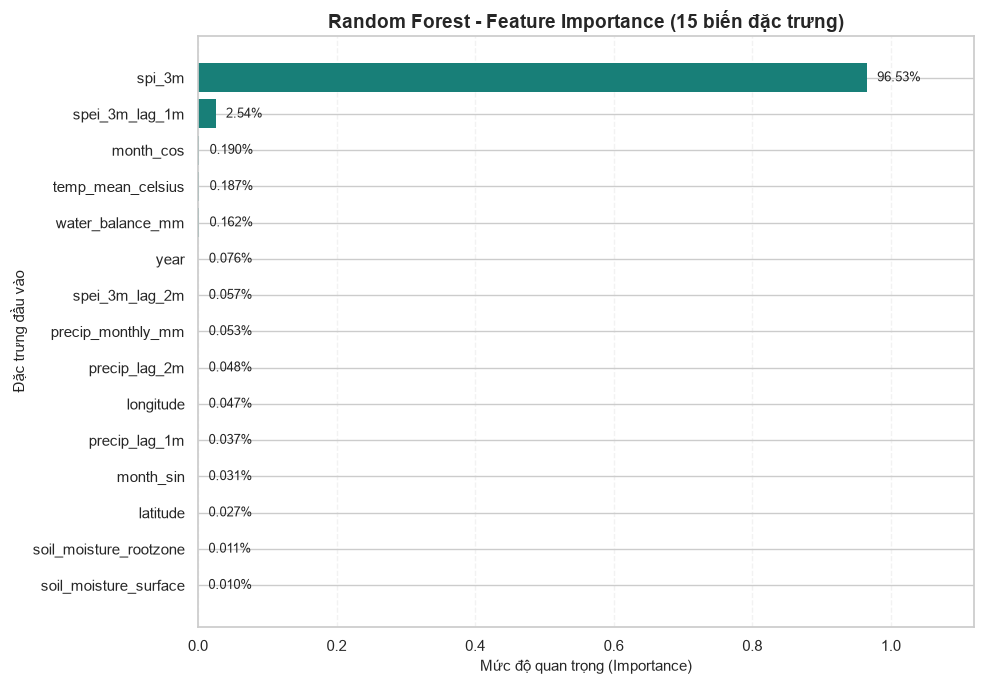

-> Đã lưu biểu đồ tại: /Users/duonghhoangnam/Drought-Prediction/reports/figures/rf_feature_importance.png


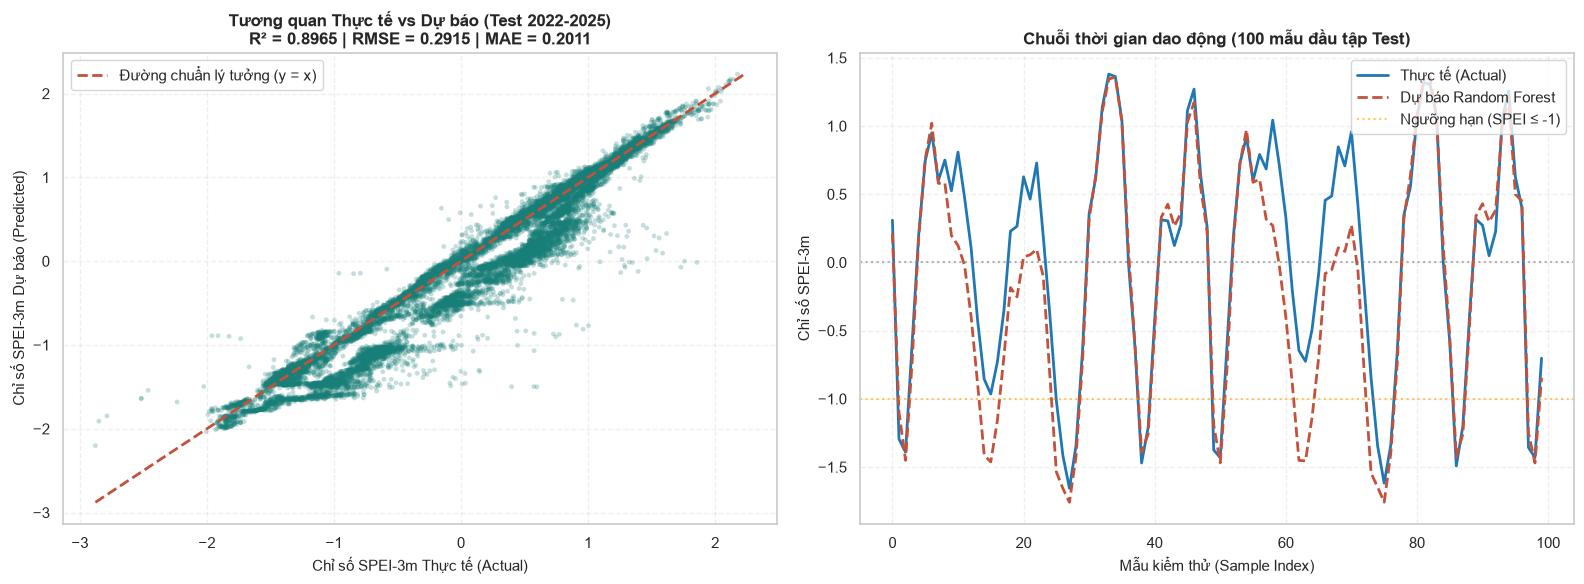

-> Đã lưu biểu đồ: /Users/duonghhoangnam/Drought-Prediction/reports/figures/rf_actual_vs_pred.png


In [8]:
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
sns.set_theme(style="whitegrid")

feature_names = getattr(rf_model, "feature_names_in", features)

importance_df = pd.DataFrame(
    { "feature": features, 
    "importance": rf_model.feature_importances_,}
).sort_values("importance", ascending=True)

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(
    importance_df["feature"],
    importance_df["importance"], 
    color="#187f78",
    edgecolor = "none",
)

ax.set_title( "Random Forest - Feature Importance (15 biến đặc trưng)", fontsize = 14, weight = "bold")
ax.set_xlabel("Mức độ quan trọng (Importance)", fontsize = 11)
ax.set_ylabel("Đặc trưng đầu vào", fontsize = 11)
ax.set_xlim(0, 1.12)
ax.grid(axis="x", alpha=0.25, linestyle="--")

for bar in bars:
    width = bar.get_width()
    txt = f"{width*100:.2f}%" if width >= 0.01 else f"{width*100:.3f}%"
    ax.text (
        width + 0.015,
        bar.get_y() + bar.get_height() / 2,
        txt,
        va = "center",
        fontsize = 9,
        color = "#222222"
    )


plt.tight_layout()
importance_path = REPORTS_FIG_DIR / "rf_feature_importance.png"
plt.savefig(importance_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"-> Đã lưu biểu đồ tại: {importance_path}")

# 2. Biểu đồ So sánh Thực tế vs Dự báo (Kết hợp Scatter Plot + Chuỗi dao động thời gian)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot A: Biểu đồ phân tán (Scatter Plot & Đường chuẩn y = x)
min_val = min(y_test.min(), y_test_pred.min())
max_val = max(y_test.max(), y_test_pred.max())
axes[0].scatter(
    y_test.values,
    y_test_pred,
    s=12,
    alpha=0.25,
    color="#187f78",
    edgecolors="none",
)
axes[0].plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--",
    color="#c4513a",
    linewidth=2,
    label="Đường chuẩn lý tưởng (y = x)",
)
axes[0].set_title(
    "Tương quan Thực tế vs Dự báo (Test 2022-2025)\n"
    f"R² = {test_metrics['r2']} | RMSE = {test_metrics['rmse']} | MAE ="
    f" {test_metrics['mae']}",
    fontsize=12,
    weight="bold",
)
axes[0].set_xlabel("Chỉ số SPEI-3m Thực tế (Actual)", fontsize=11)
axes[0].set_ylabel("Chỉ số SPEI-3m Dự báo (Predicted)", fontsize=11)
axes[0].grid(True, linestyle="--", alpha=0.3)
axes[0].legend(loc="upper left")

# Subplot B: Đường dao động theo chuỗi thời gian (100 mẫu đầu tập Test)
sample_n = 100
axes[1].plot(
    y_test.values[:sample_n],
    label="Thực tế (Actual)",
    color="#1f77b4",
    linewidth=2,
)
axes[1].plot(
    y_test_pred[:sample_n],
    label="Dự báo Random Forest",
    color="#c4513a",
    linestyle="--",
    linewidth=2,
)
axes[1].axhline(0, color="gray", linestyle=":", alpha=0.6)
axes[1].axhline(
    -1.0, color="orange", linestyle=":", alpha=0.6, label="Ngưỡng hạn (SPEI ≤ -1)"
)
axes[1].set_title(
    f"Chuỗi thời gian dao động ({sample_n} mẫu đầu tập Test)",
    fontsize=12,
    weight="bold",
)
axes[1].set_xlabel("Mẫu kiểm thử (Sample Index)", fontsize=11)
axes[1].set_ylabel("Chỉ số SPEI-3m", fontsize=11)
axes[1].grid(True, linestyle="--", alpha=0.3)
axes[1].legend(loc="upper right")

plt.tight_layout()
actual_pred_path = REPORTS_FIG_DIR / "rf_actual_vs_pred.png"
plt.savefig(actual_pred_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"-> Đã lưu biểu đồ: {actual_pred_path}")